# PHẦN 2 — Bài 5a (Trang 45): Khai phá luật kết hợp trên Online Retail (Germany)

- **Sinh viên thực hiện**: Dương Đại Phát – MSSV: `6451071058` – Lớp: `CQ.64.CNTT`
- **Nguồn dữ liệu**: `Online Retail.xlsx` (Google Drive Folder: https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m?usp=sharing, File ID: `12q4inbGbTS1UKs9sHA1X87vSRV8feEHV`)
- **Yêu cầu đề bài (Trang 45)**: Thực hiện lại đầy đủ 12 bước bài tập lập trình (trang 37–38) cho **Nước Đức (`Germany`)** với `min_sup = 5%` (`0.05`) và `min_conf = 50%` (`0.50`).


## Khởi tạo môi trường, kiểm tra thư viện và tải dữ liệu (Colab-ready)


In [1]:
print("Dương Đại Phát - 6451071058")
import os
import sys
import time
import inspect
import warnings
import subprocess

for pkg in ["mlxtend", "openpyxl", "gdown"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import mlxtend
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 140
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

DATA_FILE = "Online Retail.xlsx"
DRIVE_ID = "12q4inbGbTS1UKs9sHA1X87vSRV8feEHV"

if os.path.exists(os.path.join("datasets", DATA_FILE)):
    DATA_PATH = os.path.join("datasets", DATA_FILE)
elif os.path.exists(DATA_FILE):
    DATA_PATH = DATA_FILE
else:
    import gdown
    gdown.download(f"https://drive.google.com/uc?id={DRIVE_ID}", DATA_FILE, quiet=False)
    DATA_PATH = DATA_FILE

def make_rules(itemsets, num_tx, metric="confidence", min_threshold=0.5):
    params = inspect.signature(association_rules).parameters
    if "num_itemsets" in params:
        return association_rules(
            itemsets, num_itemsets=num_tx, metric=metric, min_threshold=min_threshold
        )
    return association_rules(itemsets, metric=metric, min_threshold=min_threshold)

print(f"mlxtend version: {mlxtend.__version__}")
print(f"Đường dẫn dữ liệu: {DATA_PATH}")


Dương Đại Phát - 6451071058


mlxtend version: 0.25.0
Đường dẫn dữ liệu: datasets\Online Retail.xlsx


## Bước 1–3: Đọc dữ liệu, tiền xử lý `Description` / `InvoiceNo` và xóa hóa đơn tín dụng `'C'`


In [2]:
print("Dương Đại Phát - 6451071058")
# Bước 1: Đọc dữ liệu
df = pd.read_excel(DATA_PATH, engine="openpyxl")
print(f"Kích thước dữ liệu ban đầu: {df.shape[0]:,} dòng x {df.shape[1]} cột")

# Bước 2: Tiền xử lý Description và InvoiceNo
df["Description"] = df["Description"].astype(str).str.strip()
df.loc[df["Description"] == "nan", "Description"] = np.nan
df.dropna(axis=0, subset=["InvoiceNo"], inplace=True)
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

# Bước 3: Xóa hóa đơn tín dụng chứa 'C'
credit_count = df["InvoiceNo"].str.contains("C", na=False).sum()
df = df[~df["InvoiceNo"].str.contains("C")].copy()
print(f"Đã xóa {credit_count:,} dòng hóa đơn tín dụng. Số dòng còn lại: {len(df):,}")
display(df.head())


Dương Đại Phát - 6451071058


Kích thước dữ liệu ban đầu: 541,909 dòng x 8 cột


Đã xóa 9,288 dòng hóa đơn tín dụng. Số dòng còn lại: 532,621


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Bước 4: Thống kê số dòng dữ liệu theo quốc gia (nhấn mạnh Germany)


Dương Đại Phát - 6451071058
Germany đứng thứ 2 toàn tập dữ liệu với 9,042 dòng (1.70%).


,Số dòng dữ liệu
Country,
United Kingdom,487622
Germany,9042
France,8408
EIRE,7894
Spain,2485
Netherlands,2363
Belgium,2031
Switzerland,1967
Portugal,1501


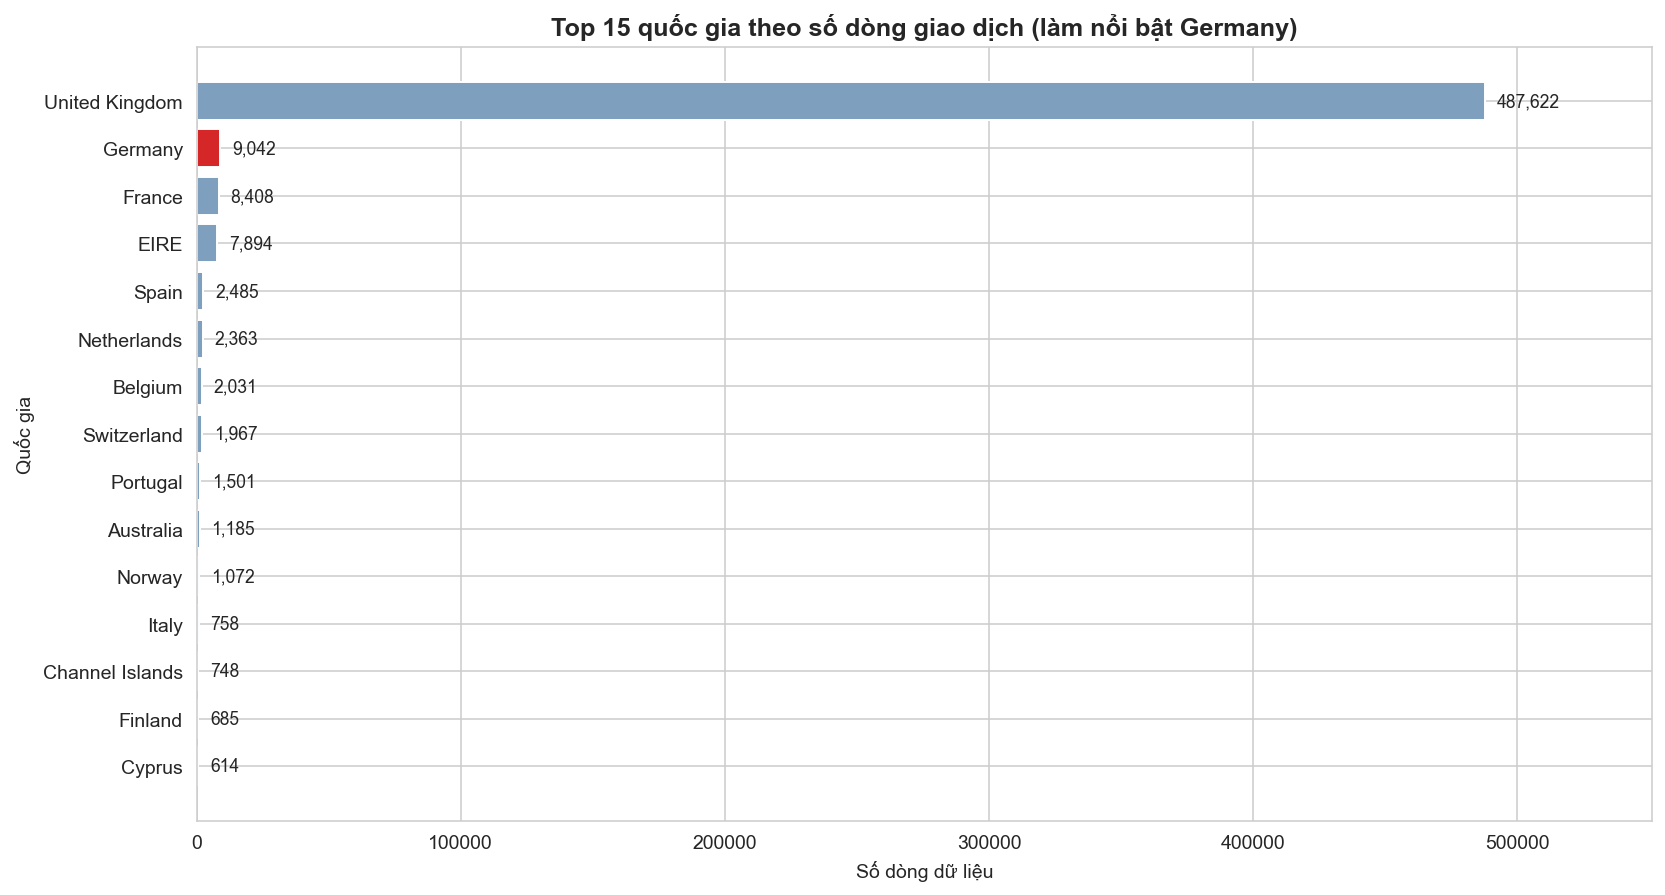

In [3]:
print("Dương Đại Phát - 6451071058")
country_counts = df["Country"].value_counts()
de_rows = country_counts.get("Germany", 0)
print(f"Germany đứng thứ 2 toàn tập dữ liệu với {de_rows:,} dòng ({de_rows / len(df) * 100:.2f}%).")
display(country_counts.head(10).to_frame("Số dòng dữ liệu"))

fig, ax = plt.subplots(figsize=(12, 6.5))
top15 = country_counts.head(15).sort_values(ascending=True)
colors = ["#d62728" if c == "Germany" else "#7f9fbf" for c in top15.index]
bars = ax.barh(top15.index, top15.values, color=colors)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 4500, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", va="center", fontsize=9)
ax.set_title("Top 15 quốc gia theo số dòng giao dịch (làm nổi bật Germany)", fontsize=13, fontweight="bold")
ax.set_xlabel("Số dòng dữ liệu")
ax.set_ylabel("Quốc gia")
ax.set_xlim(0, top15.max() * 1.13)
plt.tight_layout()
plt.show()


## Bước 5–8: Lọc dữ liệu `Germany`, tạo giỏ hàng, One-Hot Encoding và xóa `'POSTAGE'`


In [4]:
print("Dương Đại Phát - 6451071058")
# Bước 5 & 6: Lọc Germany, gom nhóm và unstack
df_de = df[df["Country"] == "Germany"]
print(f"Số dòng dữ liệu Germany: {len(df_de):,} | Số hóa đơn duy nhất: {df_de['InvoiceNo'].nunique():,}")

basket_de = (
    df_de.groupby(["InvoiceNo", "Description"])["Quantity"]
    .sum()
    .unstack()
    .reset_index()
    .fillna(0)
    .set_index("InvoiceNo")
)
print(f"Kích thước bảng giỏ hàng (trước khi xóa POSTAGE): {basket_de.shape}")

# Bước 7: One-hot encoding
def encode_data(datapoint):
    return 1 if datapoint >= 1 else 0

basket_de_ohe = basket_de.map(encode_data).astype(bool) if hasattr(basket_de, "map") else basket_de.applymap(encode_data).astype(bool)

# Bước 8: Kiểm tra và xóa cột POSTAGE
has_postage = "POSTAGE" in basket_de_ohe.columns
print(f"Cột 'POSTAGE' có trong giỏ hàng Germany không? {has_postage}")
if has_postage:
    postage_rate = basket_de_ohe["POSTAGE"].mean() * 100
    print(f"Tỷ lệ hóa đơn Germany có 'POSTAGE': {postage_rate:.2f}% -> Tiến hành xóa bỏ.")
    basket_de_ohe.drop("POSTAGE", inplace=True, axis=1)

print(f"Kích thước ma trận One-Hot Encoding Germany cuối cùng: {basket_de_ohe.shape[0]} hóa đơn x {basket_de_ohe.shape[1]} mặt hàng")
display(basket_de_ohe.iloc[:5, :8])


Dương Đại Phát - 6451071058
Số dòng dữ liệu Germany: 9,042 | Số hóa đơn duy nhất: 457
Kích thước bảng giỏ hàng (trước khi xóa POSTAGE): (457, 1695)


Cột 'POSTAGE' có trong giỏ hàng Germany không? True
Tỷ lệ hóa đơn Germany có 'POSTAGE': 81.84% -> Tiến hành xóa bỏ.
Kích thước ma trận One-Hot Encoding Germany cuối cùng: 457 hóa đơn x 1694 mặt hàng


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY
InvoiceNo,,,,,,,,
536527,False,False,False,False,False,False,False,False
536840,False,False,False,False,False,False,False,False
536861,False,False,False,False,False,False,False,False
536967,False,False,False,False,False,False,False,False
536983,False,False,False,False,False,False,False,False


## Bước 9 & 10: Apriori (`min_sup = 5%`) và Luật kết hợp (`min_conf = 50%`)


In [5]:
print("Dương Đại Phát - 6451071058")
t0 = time.perf_counter()
itemsets_de_ap = apriori(basket_de_ohe, min_support=0.05, use_colnames=True)
time_de_ap = time.perf_counter() - t0

itemsets_de_ap["length"] = itemsets_de_ap["itemsets"].apply(len)
print(f"Thời gian chạy Apriori (Germany, min_support=0.05): {time_de_ap:.4f} giây")
print(f"Tổng số tập phổ biến: {len(itemsets_de_ap)}")
display(itemsets_de_ap["length"].value_counts().sort_index().to_frame("Số tập phổ biến"))

rules_de_ap = make_rules(
    itemsets_de_ap, num_tx=len(basket_de_ohe), metric="confidence", min_threshold=0.5
)

# Xử lý sạch cả trường hợp tập tiền đề / hệ quả có nhiều hơn 1 mặt hàng bằng ', '.join(...)
rules_de_disp = rules_de_ap.copy()
rules_de_disp["antecedents_str"] = rules_de_disp["antecedents"].apply(lambda x: ", ".join(sorted(list(x)))).astype(str)
rules_de_disp["consequents_str"] = rules_de_disp["consequents"].apply(lambda x: ", ".join(sorted(list(x)))).astype(str)

print(f"\nDanh sách {len(rules_de_disp)} luật kết hợp cho Germany (min_sup=5%, min_conf=50%):")
for i in range(len(rules_de_disp)):
    row = rules_de_disp.loc[i]
    print(
        f"{i+1}. {row['antecedents_str']} ==> {row['consequents_str']} "
        f"[support={row['support']:.4f}, confidence={row['confidence']:.4f}, lift={row['lift']:.4f}]"
    )

display(
    rules_de_disp[["antecedents_str", "consequents_str", "support", "confidence", "lift"]]
    .sort_values("lift", ascending=False)
    .reset_index(drop=True)
)


Dương Đại Phát - 6451071058
Thời gian chạy Apriori (Germany, min_support=0.05): 0.0067 giây
Tổng số tập phổ biến: 59


,Số tập phổ biến
length,
1,50
2,9



Danh sách 8 luật kết hợp cho Germany (min_sup=5%, min_conf=50%):
1. PLASTERS IN TIN CIRCUS PARADE ==> PLASTERS IN TIN WOODLAND ANIMALS [support=0.0678, confidence=0.5849, lift=4.2429]
2. PLASTERS IN TIN SPACEBOY ==> PLASTERS IN TIN WOODLAND ANIMALS [support=0.0613, confidence=0.5714, lift=4.1451]
3. PLASTERS IN TIN WOODLAND ANIMALS ==> ROUND SNACK BOXES SET OF4 WOODLAND [support=0.0744, confidence=0.5397, lift=2.2021]
4. RED RETROSPOT CHARLOTTE BAG ==> WOODLAND CHARLOTTE BAG [support=0.0591, confidence=0.8438, lift=6.6482]
5. ROUND SNACK BOXES SET OF4 WOODLAND ==> ROUND SNACK BOXES SET OF 4 FRUITS [support=0.1313, confidence=0.5357, lift=3.4003]
6. ROUND SNACK BOXES SET OF 4 FRUITS ==> ROUND SNACK BOXES SET OF4 WOODLAND [support=0.1313, confidence=0.8333, lift=3.4003]
7. SPACEBOY LUNCH BOX ==> ROUND SNACK BOXES SET OF4 WOODLAND [support=0.0700, confidence=0.6809, lift=2.7781]
8. WOODLAND CHARLOTTE BAG ==> ROUND SNACK BOXES SET OF4 WOODLAND [support=0.0635, confidence=0.5000, lift=2.04

,antecedents_str,consequents_str,support,confidence,lift
0,RED RETROSPOT CHARLOTTE BAG,WOODLAND CHARLOTTE BAG,0.059081,0.843750,6.648168
1,PLASTERS IN TIN CIRCUS PARADE,PLASTERS IN TIN WOODLAND ANIMALS,0.067834,0.584906,4.242887
2,PLASTERS IN TIN SPACEBOY,PLASTERS IN TIN WOODLAND ANIMALS,0.061269,0.571429,4.145125
3,ROUND SNACK BOXES SET OF 4 FRUITS,ROUND SNACK BOXES SET OF4 WOODLAND,0.131291,0.833333,3.400298
4,ROUND SNACK BOXES SET OF4 WOODLAND,ROUND SNACK BOXES SET OF 4 FRUITS,0.131291,0.535714,3.400298
5,SPACEBOY LUNCH BOX,ROUND SNACK BOXES SET OF4 WOODLAND,0.070022,0.680851,2.778116
6,PLASTERS IN TIN WOODLAND ANIMALS,ROUND SNACK BOXES SET OF4 WOODLAND,0.074398,0.539683,2.202098
7,WOODLAND CHARLOTTE BAG,ROUND SNACK BOXES SET OF4 WOODLAND,0.063457,0.500000,2.040179


**Nhận xét về các luật kết hợp tại Germany (`min_sup = 5%`, `min_conf = 50%`):**
- Nếu không xóa `'POSTAGE'` (xuất hiện ở phần lớn đơn hàng quốc tế sang Đức), hầu hết luật kết hợp sẽ bị nhiễu bởi `'POSTAGE'`. Sau khi xóa `'POSTAGE'`, ta thu được **59 tập phổ biến** và **8 luật kết hợp** thực chất (tất cả đều có `lift > 2.0`, dao động `2.04 – 6.65`):
  - **Cặp túi `CHARLOTTE BAG`**: `RED RETROSPOT CHARLOTTE BAG ==> WOODLAND CHARLOTTE BAG` đạt độ tin cậy cao nhất (**84.38%**, `lift = 6.65`).
  - **Hộp cơm tròn `ROUND SNACK BOXES`**: `ROUND SNACK BOXES SET OF 4 FRUITS ==> ROUND SNACK BOXES SET OF4 WOODLAND` có độ hỗ trợ cao nhất (**13.13%**) và độ tin cậy **83.33%** (`lift = 3.40`); ngược lại `WOODLAND ==> 4 FRUITS` có độ tin cậy **53.57%**. Đồng thời `SPACEBOY LUNCH BOX` và `PLASTERS IN TIN WOODLAND ANIMALS` cũng thường được mua kèm `ROUND SNACK BOXES SET OF4 WOODLAND`.
  - **Nhóm băng cá nhân `PLASTERS IN TIN`**: các mẫu `CIRCUS PARADE` và `SPACEBOY` đều có xu hướng mua kèm `WOODLAND ANIMALS` (`confidence ~ 57%–58%`, `lift ~ 4.15–4.24`).


## Bước 11: Biểu đồ phân tán Support vs Confidence cho tập luật Germany


Dương Đại Phát - 6451071058


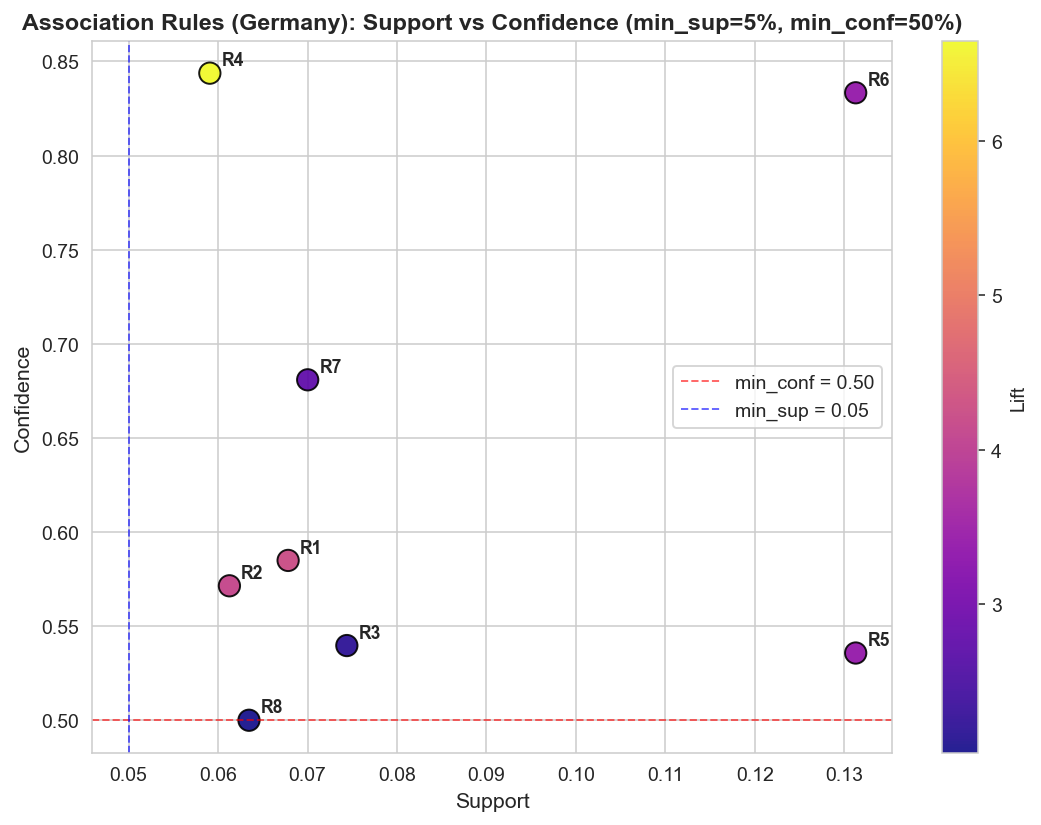

In [6]:
print("Dương Đại Phát - 6451071058")
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(
    rules_de_ap["support"],
    rules_de_ap["confidence"],
    c=rules_de_ap["lift"],
    cmap="plasma",
    s=120,
    edgecolors="black",
    alpha=0.9,
)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Lift", fontsize=10)

for idx, row in rules_de_disp.iterrows():
    ax.annotate(
        f"R{idx+1}",
        (row["support"], row["confidence"]),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=9,
        fontweight="bold",
    )

ax.set_title("Association Rules (Germany): Support vs Confidence (min_sup=5%, min_conf=50%)", fontsize=12, fontweight="bold")
ax.set_xlabel("Support", fontsize=11)
ax.set_ylabel("Confidence", fontsize=11)
ax.axhline(0.5, color="red", linestyle="--", linewidth=1, alpha=0.6, label="min_conf = 0.50")
ax.axvline(0.05, color="blue", linestyle="--", linewidth=1, alpha=0.6, label="min_sup = 0.05")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()


## Bước 12: Tìm tập phổ biến & luật kết hợp bằng FP-Growth và so sánh với Apriori


Dương Đại Phát - 6451071058


,Thuật toán,Số tập phổ biến,Số luật kết hợp,Thời gian thực thi (giây)
0,Apriori,59,8,0.00667
1,FP-Growth,59,8,0.01111


Tập phổ biến khớp nhau hoàn toàn? True
Tập luật kết hợp khớp nhau hoàn toàn? True


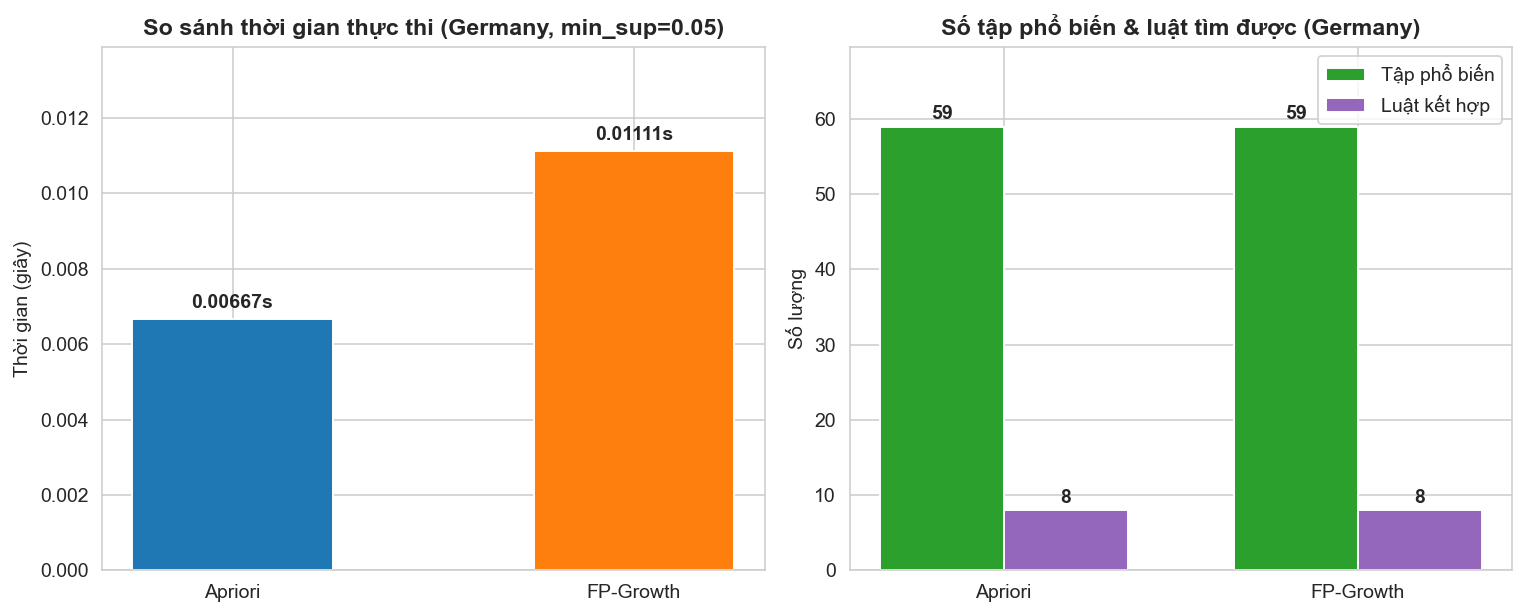

In [7]:
print("Dương Đại Phát - 6451071058")
t0 = time.perf_counter()
itemsets_de_fp = fpgrowth(basket_de_ohe, min_support=0.05, use_colnames=True)
time_de_fp = time.perf_counter() - t0

rules_de_fp = make_rules(
    itemsets_de_fp, num_tx=len(basket_de_ohe), metric="confidence", min_threshold=0.5
)

set_ap = set(itemsets_de_ap["itemsets"])
set_fp = set(itemsets_de_fp["itemsets"])
rules_ap_pairs = set(zip(rules_de_ap["antecedents"], rules_de_ap["consequents"]))
rules_fp_pairs = set(zip(rules_de_fp["antecedents"], rules_de_fp["consequents"]))

comp_de = pd.DataFrame({
    "Thuật toán": ["Apriori", "FP-Growth"],
    "Số tập phổ biến": [len(itemsets_de_ap), len(itemsets_de_fp)],
    "Số luật kết hợp": [len(rules_de_ap), len(rules_de_fp)],
    "Thời gian thực thi (giây)": [round(time_de_ap, 5), round(time_de_fp, 5)],
})
display(comp_de)
print("Tập phổ biến khớp nhau hoàn toàn?", set_ap == set_fp)
print("Tập luật kết hợp khớp nhau hoàn toàn?", rules_ap_pairs == rules_fp_pairs)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
bars1 = axes[0].bar(comp_de["Thuật toán"], comp_de["Thời gian thực thi (giây)"], color=["#1f77b4", "#ff7f0e"], width=0.5)
for b in bars1:
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.0003, f"{b.get_height():.5f}s", ha="center", fontweight="bold")
axes[0].set_title("So sánh thời gian thực thi (Germany, min_sup=0.05)", fontweight="bold")
axes[0].set_ylabel("Thời gian (giây)")
axes[0].set_ylim(0, max(comp_de["Thời gian thực thi (giây)"]) * 1.25)

x = np.arange(2)
w = 0.35
b_it = axes[1].bar(x - w/2, comp_de["Số tập phổ biến"], width=w, label="Tập phổ biến", color="#2ca02c")
b_ru = axes[1].bar(x + w/2, comp_de["Số luật kết hợp"], width=w, label="Luật kết hợp", color="#9467bd")
for b in list(b_it) + list(b_ru):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{int(b.get_height())}", ha="center", fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(comp_de["Thuật toán"])
axes[1].set_title("Số tập phổ biến & luật tìm được (Germany)", fontweight="bold")
axes[1].set_ylabel("Số lượng")
axes[1].set_ylim(0, max(comp_de["Số tập phổ biến"]) * 1.18)
axes[1].legend()

plt.tight_layout()
plt.show()


**Nhận xét so sánh (Germany, `min_sup = 5%`, `min_conf = 50%`):**
- Cả **Apriori** và **FP-Growth** cho kết quả đồng nhất 100%: **59 tập phổ biến** và **8 luật kết hợp**.
- Do tập Germany chỉ có **457 hóa đơn** và `min_sup = 5%` là ngưỡng khá cao, thời gian chạy của cả hai thuật toán đều rất nhỏ (chỉ vài mili-giây).
